# CSC 349A Numerical Analysis - Lecture 17 - Spline Interpolation
An alternative to polynomial interpolation use piecewise polynomials. 

Given $x_0, x_1, \dots, x_n$ and $f(x_0), f(x_1), \dots, f(x_n)$ 
construct a different interpolating polynomial on each subinterval: 

$$
[x_0, x_1], [x_1, x_2], \dots, [x_{n-1}, x_n] 
$$

For example piecewise linear interpolation: construct a linear polynomial on each subinterval $[x_i, x_{i+1}]$. 

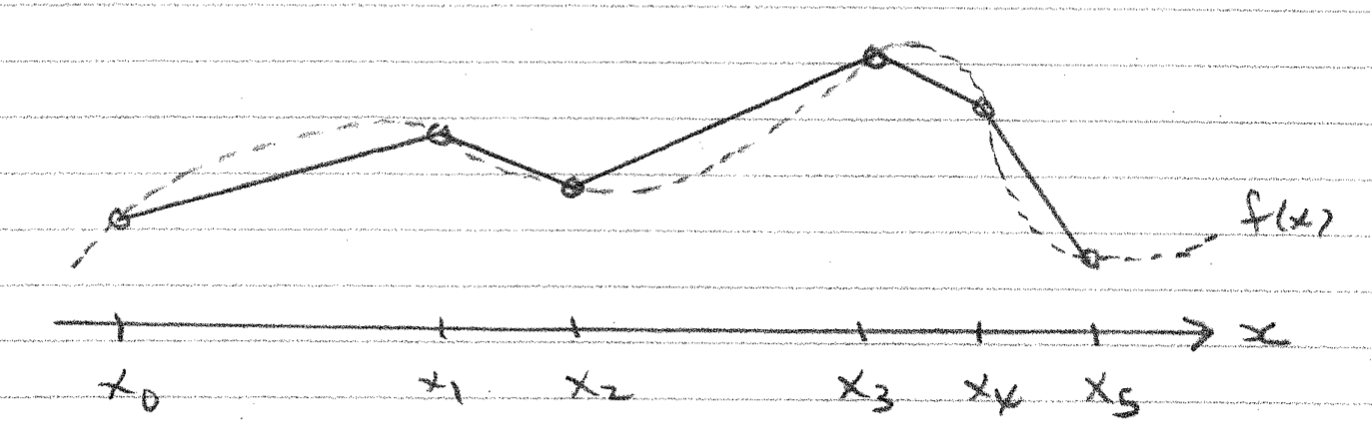

Disadvantage of piecewise linear polynomials: 
not differentiable (at points $x_i$, the knots). 

Differentiability can be obtained by using quadratic (instead of linear) 
polynomials on each $[x_i, x_{i+1}]$. 

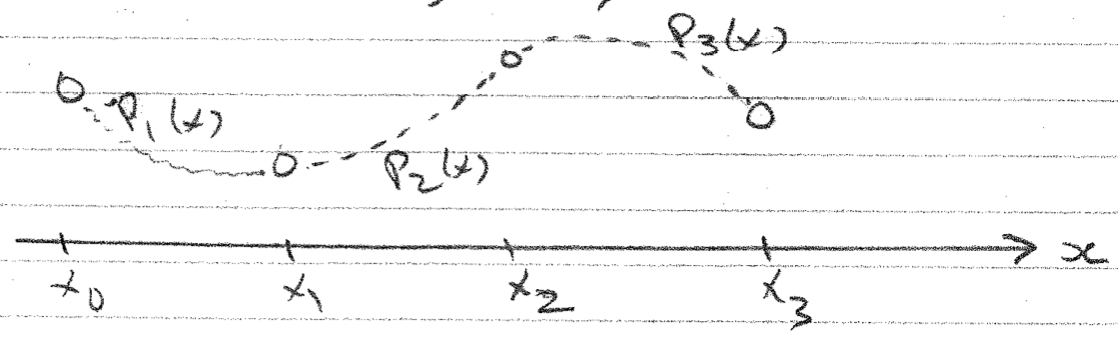

* Each $P_i(x)$ is a quadratic (and is not uniquely determined) 
* The piecewise polynomial can be made differentiable on $[x_0, x_n]$ 
* If differentiable, this is an example of a spline function 

**Definition** 
$S(x)$ is a spline function on $[x_0, x_n]$ if for some $q \geq 1$ 
1. $S(x)$ is a polynomial of degree $q$ on each subinterval $[x_i, x_{i+1}]$ 
2. $S(x)$ and its first $q-1$ derivatives are continuous on $x_0, x_n$ 

* Linear spline, $q=1$
* Quadratic spline, $q=2$
* Cubic spline, $q=3$

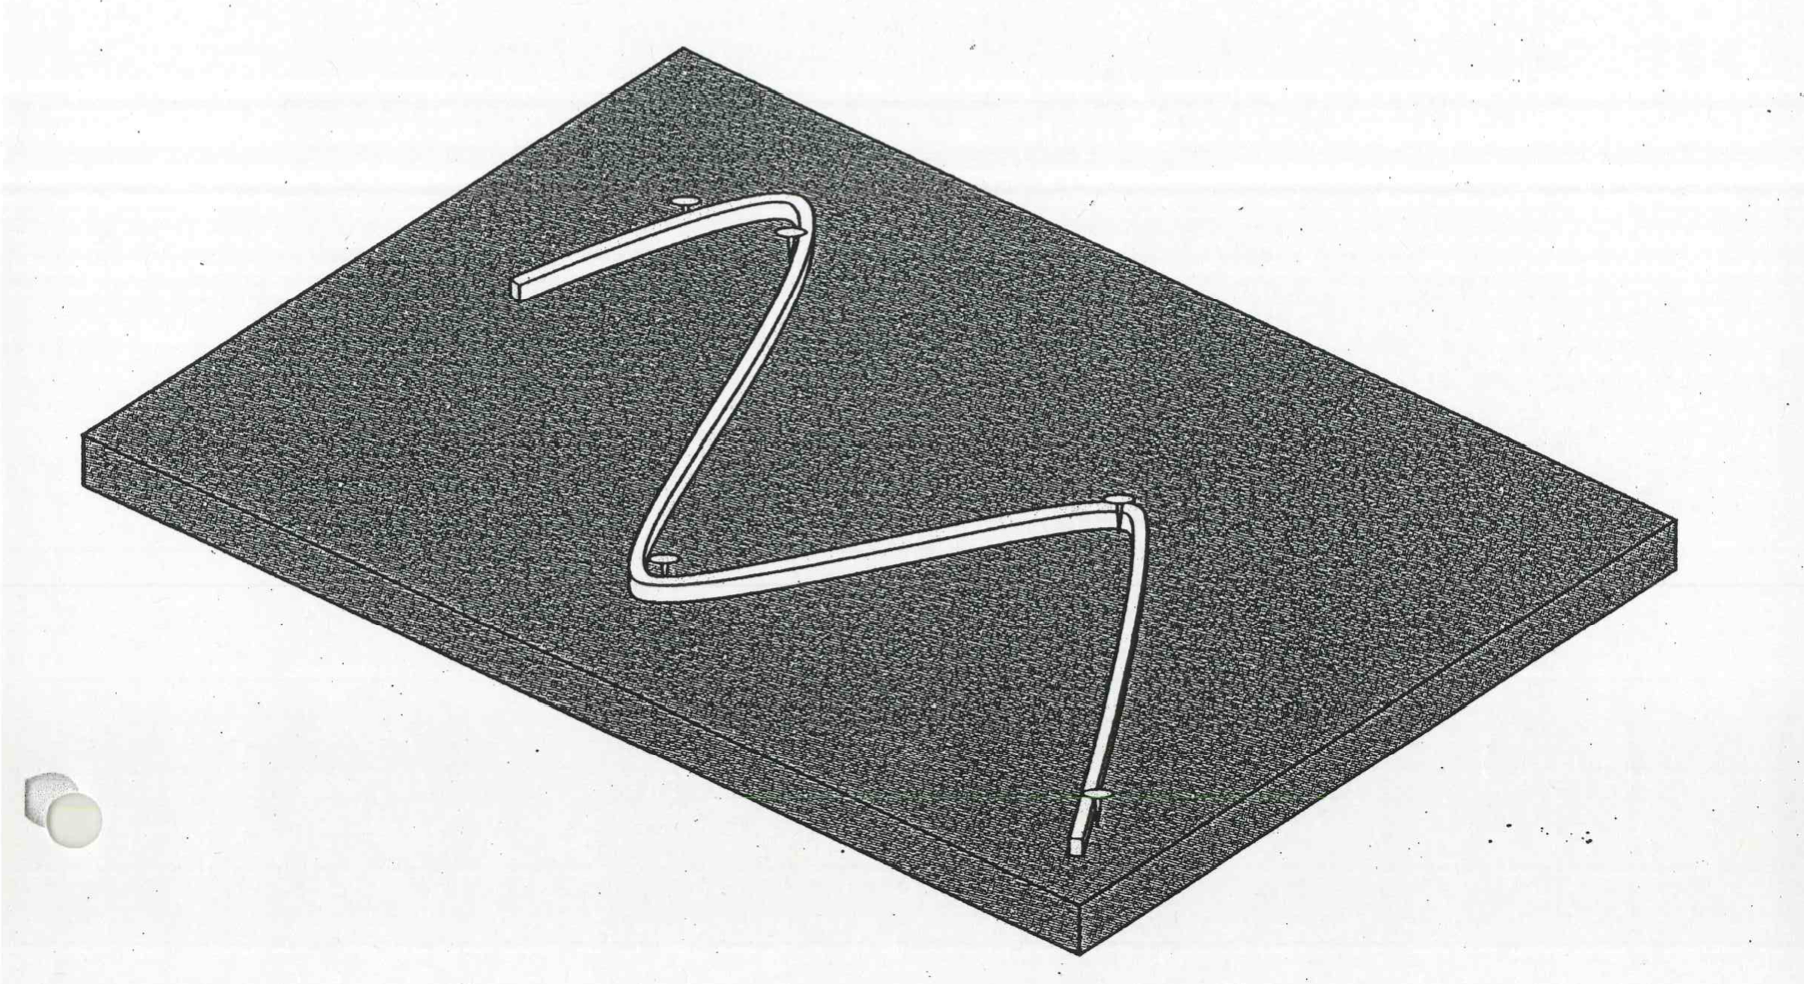

Splines were first defined by Schoenberg in 1946. Note that the definition of a spline 
function does **not** require that it interpolates some given function $f(x)$. But splines 
are often used as interpolating functions (a spline interpolant): 
* They do not have the osciallatory nature of high degree interpolating polynomials 
* the require no derivatives of $f(x)$, except possibly at the end points $x_0$ and $x_n$.  

The most common spline interpolant is **cubic**. 

## Cubic Spline Interpolants
**Definition:** Given $x_0,x_1,...,x_n$ with $x_i < x_{i+1}$ for each $i$, 
and $f(x_0), f(x_1), ..., f(x_n)$, then $S(x)$ is a **cubic spline interpolant** 
for $f(x)$ if,

(a) $S(x)$ is a cubic polynomial, denoted by $S_j(x)$, on each subinterval $[x_j,x_{j+1}]$, for $j=0,...,n-1$

(b) $S_j(x_j)=f(x_j)$, for $j=0,...,n-1$ and $S_{n-1}(x_n)=f(x_n)$

(c) $S_{j+1}(x_{j+1})=S_j(x_{j+1})$, for $j=0,...,n-2$

(d) $S'_{j+1}(x_{j+1})=S'_j(x_{j+1})$, for $j=0,...,n-2$

(e) $S''_{j+1}(x_{j+1})=S''_j(x_{j+1})$, for $j=0,...,n-2$

(f) either one of the following hold:

&emsp;&emsp;(i) $S''(x_0)=S''(x_n)=0$ (natural bounds), or

&emsp;&emsp;(ii) $S'(x_0)=f'(x_0)$ and $S'(x_n)=f'(x_n)$ (clamped bounds)


**Notes:**
* for any $f(x)$, there exist an infinite number of cubic splines satisfying conditions (a) - (e). Why?
* There are $n$ cubic polynomials $S_j(x)$ to specify, each one is defined by 4 coefficients, giving a total of $4n$ unknowns to be specified.
* However, condition (b) gives $n+1$ conditions to be satisfied, and (c), (d) and (e) each give $n-1$ conditions to be satisfied.
* Thus, there are $(n+1)+3(n-1)=4n-2$ conditions (equations) to be satisfied in $4n$ unknowns.
* But if either (i) or (ii) is also required to be satisfied, then there are $4n$ conditions in $4n$ unknowns and there exists a <u>unique</u> cubic spline interpolant satisfying (a) - (f).

### Example 1: Cubic Spline
Determine $a_0,b_0,d_0,a_1,b_1,c_1,$ and $d_1$ so that

$$
S(x) = \left\{
\begin{array}{ll}
     a_0+b_0x-3x^2+d_0x^3, & -1 \leq x\leq 0 \\
     a_1+b_1x+c_1x^2+d_1x^3, & 0 \leq x\leq 1 
\end{array}
\right. 
$$

is the natural cubic spline function such that $S(-1)=1, S(0)=2,S(1)=-1$.

**Solution**
Here, the cubic spline is expressed as

$$
S(x) = \begin{cases}
S_0(x)=a_0+b_0x-3x^2+d_0x^3, & \text{ if } 1 \leq x \leq 0 \\
S_1(x)=a_1+b_1x+c_1x^2+d_1x^3, & \text{ if } 0 \leq x \leq 1
\end{cases}
$$

and we have $x_0=-1,x_1=0,x_2=1,f(x_0)=1,f(x_1)=2,f(x_2)=-1$.

(b) \begin{equation}S_0(x_0)=f(x_0) \Rightarrow S_0(-1)=1 \Rightarrow a_0-b_0-3-d_0=1 \Rightarrow \boxed{a_0-b_0-d_0=4}\end{equation}.

\begin{equation}S_1(x_1)=f(x_1) \Rightarrow S_1(0)=2 \Rightarrow \boxed{a_1=2}\end{equation}.

\begin{equation}S_1(x_2)=f(x_2) \Rightarrow S_1(1)=-1 \Rightarrow a_1+b_1+c_1+d_1=-1 \Rightarrow \boxed{b_1+c_1+d_1=-3} \end{equation}.

(c) \begin{equation}S_1(x_1)=S_0(x_1) \Rightarrow S_1(0)=S_0(0) \Rightarrow a_1=a_0 \Rightarrow \boxed{a_0=2}\end{equation}.

(d) $S_0'(x) = b_0 -6x+3d_0x^2$ and $S_1'(x)=b_1+2c_1x+3d_1x^2$

thus

\begin{equation}S_1'(x_1)=S_0'(x_1) \Rightarrow S_1'(0)=S_0'(0) \Rightarrow b_1=b_0 \Rightarrow \boxed{b_1-b_0=0}\end{equation}.

(e)  $S_0''(x) = -6+6d_0x$ and $S_1''(x)=2c_1+6d_1x$

thus

\begin{equation}S_1''(x_1)=S_0''(x_1) \Rightarrow S_1''(0)=S_0''(0) \Rightarrow 2c_1=-6 \Rightarrow \boxed{c_1=-3}\end{equation}.

(f) To get the natural spline we use criteria (i):

\begin{equation}S_0''(x_0)=0 \Rightarrow S_0''(-1) = 0 \Rightarrow -6+6d_0(-1)=0 \Rightarrow \boxed{d_0=-1}\end{equation}.

\begin{equation}S_1''(x_2)=0 \Rightarrow S_1''(1)=0 \Rightarrow 2c_1+6d_1=0 \Rightarrow \boxed{d_1=1}\end{equation}.

So, we know that $a_0=2$, $a_1=1$, $c_1=-3$, $d_0=-1$ and $d_1=1$, that leaves the 2 unknowns $b_0$, and $b_1$ to solve. If we substitute $c_1$ and $d_1$ into equation (8) we get $b_1=-1$ and thus $b_0=-1$ by (10).

So finally the spline is,

$$
S(x) = \begin{cases}
2-x-3x^2-x^3, & \text{ if } -1 \leq x \leq 0 \\
2-x-3x^2+x^3, & \text{ if } 0 \leq x \leq 1
\end{cases}
$$

We can plot this in Python with the following commands:

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

x = np.array([-1, 0, 1])
y = np.array([1, 2, -1])
x0 = np.arange(-1, 0.01, 0.01)
x1 = np.arange(0, 1.01, 0.01)
S0 = 2 - x0 - 3*x0**2 - x0**3
S1 = 2 - x1 - 3*x1**2 + x1**3
plt.plot(x,y,'*',x0,S0,x1,S1);

In practice, we build a matrix to represent the system of equations that we solve to get the unknown coefficients. In this example, without solving along the way, we would have the following 8 equations,

\begin{eqnarray*}
a_0-b_0-d_0 &=& 4 \\
a_1 &=& 2 \\
a_1+b_1+c_1+d_1 &=& -1 \\
a_1 - a_0 &=& 0 \\
b_1 - b_0 &=& 0 \\
2c_1 &=& -6 \\
-6d_0 &=& 6 \\
2c_1 + 6d_1 &=& 0
\end{eqnarray*}

The augmented matrix $[A|b]$ is

$$
\left[
\begin{array}{rrrrrrr|r}
    1 & -1 & -1 & 0 & 0 & 0 & 0 & 4 \\
    0 & 0 & 0 & 1 & 0 & 0 & 0 & 2 \\
    0 & 0 & 0 & 1 & 1 & 1 & 1 & -1 \\
    -1 & 0 & 0 & 1 & 0 & 0 & 0 & 0 \\
    0 & -1 & 0 & 0 & 1 & 0 & 0 & 0 \\
    0 & 0 & 0 & 0 & 0 & 2 & 0 & -6 \\
    0 & 0 & -6 & 0 & 0 & 0 & 0 & 6 \\
    0 & 0 & 0 & 0 & 0 & 2 & 6 & 0
\end{array}
\right]
$$

In [ ]:
import numpy as np

A1 = np.array([1,-1,-1,0,0,0,0])
A2 = np.array([0,0,0,1,0,0,0])
A3 = np.array([0,0,0,1,1,1,1])
A4 = np.array([-1,0,0,1,0,0,0])
A5 = np.array([0,-1,0,0,1,0,0])
A6 = np.array([0,0,0,0,0,2,0])
A7 = np.array([0,0,-6,0,0,0,0])
# A8 = np.array([0,0,0,0,0,2,6])
A = np.array([A1,A2,A3,A4,A5,A6,A7])
print("A =",A)
b = np.array([[4],[2],[-1],[0],[0],[-6],[6]])
print("b =",b)
x = np.linalg.solve(A,b)
print("x =",x)

**Cubic Splines in scipy**

There is an algorithm for cubic spline computation given in the text but it has a different derivation than what we have done and different from Python. In Python (scipy), they use a different form for the splines. For example, when $n=3$, the default uses the following form for the cubic polynomials:

\begin{align}
     S_0(x) &= a_0+b_0(x-x_0)+c_0(x-x_0)^2+d_0(x-x_0)^3 \\
     S_1(x) &= a_1+b_1(x-x_1)+c_1(x-x_1)^2+d_1(x-x_1)^3 \\
     S_2(x) &= a_2+b_2(x-x_2)+c_2(x-x_2)^2+d_2(x-x_2)^3
\end{align}

Note that, with this form, $a_0=f(x_0), a_1=f(x_1),$ and $a_2=f(x_2)$. This simplifies the system somewhat. 

## Quadratic Spline Interpolants
Construction of quadratic splines is similar to that of cubic splines but there are only $3n$ 
unknown coefficients and you do not need to set the second derivatives of the interior knots to 
be equal. That is, we do not create the (e) equations from above. As such, the (b) to (d) equations 
total $3n-1$, meaning that we also only need one extra (f) equation. Often we use $Q''(x_0)=0$ or, 
as is the case with the next example, we assign one of the coefficients before hand.

### Example 2: Quadratic Spline

Determine $a,b,c,d,$ and $e$ so that

$$
Q(x) = \left\{
\begin{array}{ll}
      ax^2+x+b, & -1 \leq x\leq 0 \\
     cx^2+dx+e, & 0 \leq x\leq 1 
\end{array}
\right. 
$$

is a quadratic spline function that interpolates $f(x)$ where $f(-1)=1, f(0)=1,f(1)=1$.

**Solution**

(a) Here, the quadratic spline is expressed as

$$
Q(x) = \begin{cases}
Q_0(x)=ax^2+x+b, & \text{ if } -1 \leq x \leq 0 \\
Q_1(x)=cx^2+dx+e, & \text{ if } 0 \leq x \leq 1
\end{cases}
$$

and we have $x_0=-1,x_1=0,x_2=1,f(x_0)=1,f(x_1)=1,f(x_2)=1$. Notice that I have given you one coefficient, 
meaning we only have five unkowns here and thus need only five equations. This means I won't need boundary 
conditions in this case (no (f) criteria). Also, for quadratic splines we never have the (e) conditions.

(b) \begin{equation}Q_0(x_0)=f(x_0) \Rightarrow Q_0(-1)=f(-1) \Rightarrow a-1+b=1 \Rightarrow \boxed{a+b=2} \end{equation}.

\begin{equation}Q_1(x_1)=f(x_1) \Rightarrow Q_1(0)=f(0) \Rightarrow \boxed{e=1}\end{equation}.

\begin{equation}Q_1(x_2)=f(x_2) \Rightarrow Q_1(1)=f(1) \Rightarrow \boxed{c+d+e=1}\end{equation}.

(c) \begin{equation}Q_1(x_1)=Q_0(x_1) \Rightarrow Q_1(0)=Q_0(0) \Rightarrow e=b \Rightarrow \boxed{e-b=0}\end{equation}.

(d) $Q_0'(x) = 2ax+1$ and $Q_1'(x)=2cx+d$

thus

\begin{equation}Q_1'(x_1)=Q_0'(x_1) \Rightarrow Q_1'(0)=Q_0'(0) \Rightarrow \boxed{d=1}\end{equation}.

Here, we need to solve the above system of five equations in five unknowns. This one is simple enough that 
we can do it manually with equation substitutions. Thus, substituting equations (2) and (5) in (3) we get 
$c=-1$. Substituting (2) in (4) gives $b=1$, and substituting that into (1) gives $a=1$.

So, $a=1, b=1, c=-1,d=1,e=1$ and so finally the spline is,

$$
Q(x) = \begin{cases}
x^2+x+1, & \text{ if } -1 \leq x \leq 0 \\
-x^2+x+1, & \text{ if } 0 \leq x \leq 1
\end{cases}
$$

Plot this spline with the following commands:

In [ ]:
x = np.array([-1, 0, 1])
y = np.array([1, 1, 1])
x0 = np.arange(-1, 0.01, 0.01)
x1 = np.arange(0, 1.01, 0.01)
q0 = x0**2 +x0 + 1
q1 =- x1**2 + x1 +1
plt.plot(x,y,'*',x0,q0,x1,q1);